In [35]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate

In [244]:
import gc


In [36]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [37]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [38]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [39]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [40]:
import astropy.units as u
from astropy.modeling.models import Moffat1D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat1D.html
from astropy.modeling.functional_models import Moffat2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat2D.html


In [41]:
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import PchipInterpolator
from tqdm.auto import tqdm
import math

In [42]:
# Standard and scientific packages
# import sys
# from pathlib import Path
# import numpy as np
# import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy.signal import fftconvolve
from astropy.modeling.models import Sersic2D
# from tqdm.auto import tqdm

### Point source coupling jitter effect

In [43]:
def sigma_jitter_milliarcsec_to_metres(sigma_jitter_rms, focal_length, demagnification): 
    """
    Convert the RMS jitter from milliarcseconds to metres at the fibre plane.

    Parameters: 
    sigma_jitter_rms : float
        RMS jitter in milliarcseconds.
    focal_length : float
        Focal length of the telescope in metres.
    demagnification : float 
        Demagnification factor from the telescope focal plane to the fibre plane, done by the reimaging optics. 

    Returns:
    float
        RMS jitter in metres at the fibre plane.
    """
    # Convert jitter from milliarcseconds to radians
    sigma_theta_radians = sigma_jitter_rms * 1e-3 / 206265 

    # Convert jitter from radians to physical units (metres) at the fibre plane using the focal length and demagnification

    sigma_jitter_metres = demagnification * focal_length * sigma_theta_radians

    return sigma_jitter_metres

In [44]:
def generate_jitter_positions(
    sigma_jitter_rms_mas: float,
    focal_length: float,
    demagnification: float,
    n_samples: int,
    rng: np.random.Generator
) -> tuple[np.ndarray, np.ndarray]:
    """
    Generate random x and y tip-tilt jitter displacements at the fibre plane. 
    The displacements are drawn from a normal distribution with mean 0 and standard deviation corresponding to 
    the RMS jitter specified in milliarcseconds.
    This is a helper function to generate random jitter positions for Monte Carlo simulations of coupling efficiency.

    Parameters
    ----------
    sigma_jitter_rms_mas:
        RMS jitter in milliarcseconds.

    focal_length:
        Telescope focal length in metres.

    demagnification:
        Demagnification factor between the telescope focal plane
        and the fibre plane.

    n_samples:
        Number of random jitter positions.

    rng:
        NumPy random number generator.

    Returns
    -------
    delta_x, delta_y:
        Random x and y jitter displacements at the fibre plane, in metres.
    """

    # Convert RMS jitter from milliarcseconds to metres at the fibre plane.
    sigma_jitter_metres = sigma_jitter_milliarcsec_to_metres(
        sigma_jitter_rms_mas,
        focal_length,
        demagnification
    )

    # Generate random x jitter positions.
    delta_x = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    # Generate random y jitter positions.
    delta_y = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    return delta_x, delta_y

In [45]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# numerical aperture of fibre
NA = 0.1 

# # Calculate the normalised frequency (V-number) of the fibre
# V = 2 * pi * (a / lam0) * NA
# print(f"V-number of the fibre: {V:.2f}")

In [46]:
f_coude = 399
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9
D_M1 = 8.0
D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [47]:
r_max = 125e-6  # maximum radial distance from the fibre centre, in metres
x_1d = np.linspace(-r_max, r_max, 1000) # x-coordinates at the fibre plane, in metres
y_1d = np.linspace(-r_max, r_max, 1000) # y-coordinates at the fibre plane, in metres
x, y = np.meshgrid(x_1d, y_1d)

In [48]:
# Only test for a single normalised frequency at r=5.7microns for my first test of decentred position
prepared_smf_mode_5p7micron = prepare_modes_2d(
                                x, y,
                                a=5.7e-6, 
                                NA=NA, 
                                lam0=lam0, 
                                az_sym=False, 
                                mode_case="few_mode"
                            )

## Define function that sweeps the jitter affected coupling efficiency as a function of radius

In [49]:
# Fibre front grid in metres

r_max = 125e-6 # maximum radius of the CLADDING region to be considered in the 2D grid, in meters
n_grid = 1000 

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [50]:
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0


def V_to_radius_um_axis(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6

In [51]:
V_to_radius_um_axis(2.405)

5.741514572040124

In [52]:
core_radius_range_full = np.linspace(2.5e-6, 30e-6, 276) # fibre core radius range in metres

In [53]:
core_radius_range_smf = core_radius_range_full[core_radius_range_full <= 5.7415e-6]
# eta_fixed_list_smf = eta_tot_psf_radial_decentre_list[:len(core_radius_range_smf)]

## Coupling detailed modes displacement specific calculation

In [54]:
def make_larger_image_grid(
        x_1d,
        y_1d,
        r_max_large,
):
    """
    Create a larger image-plane grid while preserving approximately
    the same spatial sampling as the original grid.

    Parameters
    ----------
    x_1d, y_1d : 1D arrays
        Original image-plane coordinate grids.

    r_max_large : float
        Half-width of the larger image-plane field in metres.

    Returns
    -------
    x_large, y_large : 2D arrays
        Larger image-plane coordinate matrices.

    x_large_1d, y_large_1d : 1D arrays
        Larger image-plane coordinate grids.
    """

    dx = x_1d[1] - x_1d[0]
    dy = y_1d[1] - y_1d[0]

    n_x_large = int(
        np.round(
            2 * r_max_large / dx
        )
    ) + 1

    n_y_large = int(
        np.round(
            2 * r_max_large / dy
        )
    ) + 1

    x_large_1d = np.linspace(
        -r_max_large,
        r_max_large,
        n_x_large
    )

    y_large_1d = np.linspace(
        -r_max_large,
        r_max_large,
        n_y_large
    )

    x_large, y_large = np.meshgrid(
        x_large_1d,
        y_large_1d
    )

    return (
        x_large,
        y_large,
        x_large_1d,
        y_large_1d
    )

In [55]:
from scipy.interpolate import RegularGridInterpolator


def make_E_image_interpolator(
        E_image,
        x_image_1d,
        y_image_1d,
):
    """
    Create an interpolator for a complex electric field.

    The electric field may be defined on either:
        1. the same grid as the fibre-overlap calculation, or
        2. a larger image-plane grid.

    Parameters
    ----------
    E_image : 2D complex array
        Centred electric field of the astronomical image.

    x_image_1d, y_image_1d : 1D arrays
        Coordinate grids corresponding to E_image.

    Returns
    -------
    E_interpolator : RegularGridInterpolator
        Interpolator for the complex electric field.
    """

    E_image = np.asarray(
        E_image
    )

    x_image_1d = np.asarray(
        x_image_1d
    )

    y_image_1d = np.asarray(
        y_image_1d
    )

    if E_image.shape != (
        len(y_image_1d),
        len(x_image_1d)
    ):
        raise ValueError(
            "E_image dimensions must match "
            "(len(y_image_1d), len(x_image_1d))."
        )

    E_interpolator = RegularGridInterpolator(
        (
            y_image_1d,
            x_image_1d
        ),
        E_image,
        method="linear",
        bounds_error=False,
        fill_value=0.0
    )

    return E_interpolator

In [56]:
def spatially_shift_E_image_2d(
        E_interpolator, 
        x, y, 
        shift_x=0.0, 
        shift_y=0.0, 
): 
    """
    Spatially shift a complex electric field onto a fiexed output grid. 

    A positive shift_x moves the astronomical image toward + x. 
    A positive shift_y moves the astronomical image toward + y.

    The shifted field is:

        E_shifted(x, y)
            = E_centred(x - shift_x, y - shift_y)

    Parameters
    ----------
    E_interpolator : RegularGridInterpolator
        Interpolator of the centred electric field.

    x, y : 2D arrays
        Fixed fibre-plane coordinate grids.

    shift_x, shift_y : float
        Spatial displacement of the image in metres.

    Returns
    -------
    E_image_shifted : 2D complex array
        Shifted electric field evaluated on the fixed fibre grid.

    I_image_shifted : 2D array
        Corresponding shifted intensity.

    """

    # Coordinates in the original centred electric field grid corresponding to the shifted image
    interpolation_points = np.column_stack((y - shift_y).ravel(), (x - shift_x).ravel()) # ravel() flattens the arrays to 1D, and column_stack combines them into a 2D array of shape (N, 2)

    # Evaluate the centred electric field at the shifted coordinates
    E_image_shifted = E_interpolator(interpolation_points).reshape(x.shape)

    # Calculate the intensity from teh shifted electric field
    I_image_shifted = np.abs(E_image_shifted)**2

    return E_image_shifted, I_image_shifted


In [57]:
def shift_and_extract_E_image_2d(
        E_interpolator,
        x,
        y,
        shift_x=0.0,
        shift_y=0.0,
):
    """
    Spatially shift an electric field and evaluate only the fixed
    fibre-overlap field of view.

    The source electric field may be defined over a larger physical
    field than the output x, y grid.

    The returned field always has the same dimensions and physical
    field of view as x and y.

    A positive shift_x moves the astronomical image toward +x.
    A positive shift_y moves the astronomical image toward +y.

    The shifted field is

        E_shifted(x, y)
            = E_centred(x - shift_x, y - shift_y)

    Parameters
    ----------
    E_interpolator : RegularGridInterpolator
        Interpolator of the centred electric field.

    x, y : 2D arrays
        Fixed fibre-overlap coordinate grid.

        For example:
            shape = (1000, 1000)
            FOV = -125 to +125 microns.

    shift_x, shift_y : float
        Spatial displacement in metres.

    Returns
    -------
    E_image_shifted : 2D complex array
        Shifted electric field evaluated only over the fixed
        fibre-overlap field of view.

    I_image_shifted : 2D array
        Corresponding intensity distribution.
    """

    # Coordinates in the larger centred electric-field image
    # corresponding to the shifted source.
    interpolation_points = np.column_stack((
        (y - shift_y).ravel(),
        (x - shift_x).ravel()
    ))

    # Evaluate the larger electric field only at the coordinates
    # required by the fixed overlap grid.
    E_image_shifted = E_interpolator(
        interpolation_points
    ).reshape(
        x.shape
    )

    # Calculate the corresponding intensity.
    I_image_shifted = (
        np.abs(E_image_shifted)**2
    )

    return (
        E_image_shifted,
        I_image_shifted
    )

In [58]:
def radial_displacement(
    x_displacement,
    y_displacement,
    misalignment=0.0,
    misalignment_angle=0.0
):
    """
    Calculate radial displacement including a fixed fibre misalignment.

    Parameters
    ----------
    x_displacement, y_displacement : float or array
        Random/source displacement in x and y.

    misalignment : float, optional
        Magnitude of the fixed fibre misalignment.

    misalignment_angle : float, optional
        Direction of the fixed misalignment in radians.

    Returns
    -------
    radial_displacement : float or array
        Total source-fibre radial separation.
    """

    x_misalignment = misalignment * np.cos(misalignment_angle)
    y_misalignment = misalignment * np.sin(misalignment_angle)

    x_total = x_displacement + x_misalignment
    y_total = y_displacement + y_misalignment

    return np.sqrt(x_total**2 + y_total**2)

In [59]:
def total_eff_2d_coherent_galaxy(
    prepared_modes, 
    x, y, 
    x_1d, y_1d, 
    E_interpolator, 
    decentre=(0.0, 0.0),
): 
    """
    Calculate the total and individual coupling efficiency of a coherent galaxy electric field.

    Unlike total_eff_2d(), this function does not generate a
    diffraction-limited point-source electric field.

    Instead, the precomputed coherent galaxy electric field is
    spatially shifted using interpolation and evaluated on the
    fixed fibre-overlap grid.

    Parameters
    ----------
    prepared_modes : list
        Fibre modes returned by prepare_modes_2d().

    x, y : 2D arrays
        Fixed fibre-plane coordinate grids.

    x_1d, y_1d : 1D arrays
        Fixed fibre-plane coordinate grids.

    E_interpolator : RegularGridInterpolator
        Interpolator of the centred coherent galaxy electric field.
        The original electric field may be defined on either the
        same grid or a larger physical field of view.

    decentre : tuple
        Spatial shift (dx, dy) of the galaxy relative to the fibre.

    Returns
    -------
    eta_total : float
        Total coupling efficiency summed over all supported modes.

    mode_results : list
        Coupling efficiency of each individual fibre mode.
    """

    dx, dy = decentre

    # Spatially shift the coherent galaxy electric field and evaluate
    # it only on the fixed fibre-overlap grid.
    E_image, I_image = shift_and_extract_E_image_2d(
        E_interpolator=E_interpolator,
        x=x,
        y=y,
        shift_x=dx,
        shift_y=dy
    )

    # Calculate the coupling to every supported fibre mode.
    # Begin with zero efficiency before accumulating eta for each mode.
    total = 0.0

    # Array of dictionaries containing mode results.
    mode_results = []

    # For each existing mode in the prepared_modes list,
    # calculate eta for that mode.
    for mode in prepared_modes:

        eta, num, den = coupling_efficiency_2d(
            E_image,
            mode["E_mode"],
            x_1d,
            y_1d
        )

        # Accumulate coupling efficiency of each mode
        # to obtain the total coupling efficiency.
        total += eta

        mode_results.append({
            "l": mode["l"],
            "m": mode["m"],
            "cutoff_V": mode["cutoff_V"],
            "X_root": mode["X_root"],
            "Y_root": mode["Y_root"],
            "angular": mode["angular"],
            "eta": eta
        })

    return total, mode_results

In [60]:
def jittered_coherent_galaxy_eta_per_mode_vs_core_radius(
        core_radius_array, 
        x, y,
        x_1d, y_1d,
        E_galaxy,
        delta_x, delta_y,
        NA, lam0, 
        x_E_image_1d=None,
        y_E_image_1d=None,
        acceptance_radius="core_radius",
        mode_case="few_mode",
        az_sym=False,
        fibre_offset_x=0.0,
        fibre_offset_y=0.0,
        n_jobs=1,
):
    """ 
    Calculate the jitter-averaged coherent-galaxy coupling efficiency
    for each individual fibre mode as a function of fibre core radius.

    The coherent galaxy electric field is spatially shifted for each
    Monte Carlo tip-tilt realization using interpolation.

    The galaxy electric field may be defined on:
        1. the same grid as the fibre-overlap calculation, or
        2. a larger physical field of view.

    In both cases, the shifted field is evaluated only on the fixed
    fibre-overlap grid defined by x, y, x_1d and y_1d.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii.

    x, y : 2D arrays
        Fixed fibre-overlap coordinate matrices.

    x_1d, y_1d : 1D arrays
        Fixed fibre-overlap coordinate grids.

    E_galaxy : 2D complex array
        Centred coherent galaxy electric field.
    
    x_E_image_1d, y_E_image_1d : 1D arrays, optional
        Coordinate grids corresponding to E_galaxy. 

        If None, x_1d and y_1d are used. 

        These may describe a larger source field, E.g. ±150 microns, 
        while x_1d and y_1d remain the fixed ±125 micron overlap grid. 
    
    delta_x, delta_y : arrays
        Monte Carlo jitter samples in x and y

    acceptance_radius : {"core_radius", None, "two_cases_test"}
        "core_radius"
            Jitter realizations whose galaxy centre lies outside
            the fibre core radius are assigned zero coupling.

        None
            No hard spatial acceptance boundary is imposed.

        "two_cases_test"
            Calculate all jitter realizations once and return:
                1. the result with no hard boundary, and
                2. the same result with a hard core-radius boundary.

    fibre_offset_x, fibre_offset_y : float, optional
        Fixed displacement of the fibre centre relative to the nomial optical axis. 

    """
    # Store the results for every core radius.
    # results_all_radius = []

    delta_x = np.asarray(delta_x)
    delta_y = np.asarray(delta_y)

    if delta_x.shape != delta_y.shape:
        raise ValueError("delta_x and delta_y must have the same shape.")

    n_samples = len(delta_x) # number of jittered point source positions

    # Coorinates corresponding to the supplied galaxy field
    if x_E_image_1d is None:
        x_E_image_1d = x_1d
    if y_E_image_1d is None:
        y_E_image_1d = y_1d

    # Create the coherent galaxy electric field interpolator ONCE

    E_interpolator = make_E_image_interpolator(
        E_image=E_galaxy,
        x_image_1d=x_E_image_1d,
        y_image_1d=y_E_image_1d
    )


    # ---------------------------------------------------------
    # Effective galaxy position relative to the actual fibre centre
    # ---------------------------------------------------------
    # Here fibre_offset_x/y describe where the fibre centre is relative to the nominal optical axis.
    # Therefore, galaxy centre relative to fibre = source position - fibre position
    effective_delta_x = delta_x - fibre_offset_x
    effective_delta_y = delta_y - fibre_offset_y

    # Calculate this ONCE because it does not depend on core radius
    radial_displacement = np.sqrt(effective_delta_x**2 + effective_delta_y**2)

    # ---------------------------------------------------------
    # Loop through fibre core radii
    # ---------------------------------------------------------
    # for a in core_radius_array:

    # ---------------------------------------------------------
    # Calculate the coupling efficiency for one fibre core radius.
    # This function will be run in parallel for different core radii.
    # ---------------------------------------------------------
    def run_one_radius(a):

        prepared_modes = prepare_modes_2d(
            x,
            y,
            a=a,
            NA=NA,
            lam0=lam0,
            az_sym=az_sym,
            mode_case=mode_case,
        )

        # ---------------------------------------------------------
        # Determine which jitter positions need to be calculated
        # ---------------------------------------------------------

        if acceptance_radius == "core_radius":

            acceptance_radius_adjusted = a

            inside_acceptance = (
                radial_displacement
                <= acceptance_radius_adjusted
            )

        elif acceptance_radius is None:

            acceptance_radius_adjusted = None

            inside_acceptance = np.ones(
                n_samples,
                dtype=bool
            )

        elif acceptance_radius == "two_cases_test":

            # Calculate every jitter realization once.
            # The core-radius mask will be applied afterwards.
            acceptance_radius_adjusted = a

            inside_acceptance = np.ones(
                n_samples,
                dtype=bool
            )

        else:

            raise ValueError(
                "acceptance_radius must be "
                "'core_radius', None, or 'two_cases_test'."
            )
        
        # Store the total coupling efficiency for every jitter position.
        # Positions outside the acceptance radius remain zero.
        eta_samples_total = np.zeros(n_samples)

        # Create one array of coupling efficiencies for every supported fibre mode.
        # Each array has one value for every Monte Carlo jitter position.
        eta_samples_modes = {}

        for mode in prepared_modes:

            # Create a label for the current fibre mode. 
            if mode["l"] == 0:
                mode_label = f'LP0{mode["m"]}'
            else:
                mode_label = (
                    f'LP{mode["l"]}{mode["m"]} '
                    f'{mode["angular"]}'
                )

            # Initialise all jitter positions to zero coupling.
            eta_samples_modes[mode_label] = np.zeros(n_samples)

        # Calculate coupling efficiency only for point source positions that are within the acceptance radius.
        for i in np.where(inside_acceptance)[0]:

            eta_total, mode_results = total_eff_2d_coherent_galaxy(
                    prepared_modes=prepared_modes,
                    x=x, y=y,
                    x_1d=x_1d,
                    y_1d=y_1d,
                    E_interpolator=E_interpolator,
                    decentre=(effective_delta_x[i], effective_delta_y[i])
                )

            # Store the total coupling efficiency at this jitter position.
            eta_samples_total[i] = eta_total

            # Store the coupling efficiency of every individual mode
            # at this jitter position.
            for mode_result in mode_results:

                if mode_result["l"] == 0:
                    mode_label = (
                        f'LP0{mode_result["m"]}'
                    )
                else:
                    mode_label = (
                        f'LP{mode_result["l"]}'
                        f'{mode_result["m"]} '
                        f'{mode_result["angular"]}'
                    )

                eta_samples_modes[mode_label][i] = (
                    mode_result["eta"]
                )

        # ---------------------------------------------------------
        # Special case: return both masked and unmasked results
        # ---------------------------------------------------------

        if acceptance_radius == "two_cases_test":

            # ---------------------------------------------
            # Case 1: no hard boundary
            # ---------------------------------------------

            eta_total_mean_no_mask = np.mean(eta_samples_total)

            eta_mode_mean_no_mask = {mode_label: np.mean(eta_samples) 
                                     for mode_label, eta_samples in eta_samples_modes.items()}


            # ---------------------------------------------
            # Case 2: hard boundary at fibre core radius
            # ---------------------------------------------

            inside_core_radius = radial_displacement <= a

            eta_samples_total_core_mask = eta_samples_total.copy()

            eta_samples_total_core_mask[~inside_core_radius] = 0.0

            eta_samples_modes_core_mask = {}

            for mode_label, eta_samples in eta_samples_modes.items():

                eta_masked = eta_samples.copy()

                eta_masked[~inside_core_radius] = 0.0

                eta_samples_modes_core_mask[mode_label] = eta_masked

            eta_total_mean_core_mask = np.mean(eta_samples_total_core_mask)

            eta_mode_mean_core_mask = {mode_label: np.mean(eta_samples) 
                                       for mode_label, eta_samples 
                                       in eta_samples_modes_core_mask.items()
            }

            return {
                "core_radius": a,
                "no_mask": {
                    "eta_total_mean": eta_total_mean_no_mask,
                    "eta_total_samples": eta_samples_total,
                    "eta_mode_mean": eta_mode_mean_no_mask,
                    "eta_mode_samples": eta_samples_modes,
                },
                "core_radius_mask": {
                    "eta_total_mean": eta_total_mean_core_mask,
                    "eta_total_samples": eta_samples_total_core_mask,
                    "eta_mode_mean": eta_mode_mean_core_mask,
                    "eta_mode_samples": eta_samples_modes_core_mask,
                },
                "inside_core_radius": inside_core_radius,
            }

        # ---------------------------------------------------------
        # Normal single-case result
        # ---------------------------------------------------------

        eta_mean_total = np.mean(eta_samples_total)

        eta_mean_modes = {
            mode_label: np.mean(eta_samples)
            for mode_label, eta_samples in eta_samples_modes.items()
        }

        return {
            "core_radius": a,
            "eta_total_mean": eta_mean_total,
            "eta_total_samples": eta_samples_total,
            "eta_mode_mean": eta_mean_modes,
            "eta_mode_samples": eta_samples_modes,
            "inside_acceptance": inside_acceptance,
        }

    # ---------------------------------------------------------
    # Parallel processing over fibre core radius
    # ---------------------------------------------------------

    if n_jobs == 1:
        results_all_radius = [
            run_one_radius(a)
            for a in core_radius_array
        ]

    else:
        results_all_radius = Parallel(
            n_jobs=n_jobs,
            backend="threading",
            verbose=10
        )(
            delayed(run_one_radius)(a)
            for a in core_radius_array
        )

    return results_all_radius

In [61]:
# Telescope and fibre
lam0 = 1.5e-6                         # Wavelength [m]
NA = 0.1                              # Fibre numerical aperture
F_focus = 49.9                        # Coudé focal ratio before demagnification
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / F_focus
D_M1 = 8.0                            # Primary mirror diameter [m]
D_obstruction = 1.0                   # Central obstruction diameter [m]
alpha_vlt = D_obstruction / D_M1
rad_to_arcsec = (180 / np.pi) * 3600

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)
plate_scale_demag = plate_scale_coude / Magnification
f_eff = rad_to_arcsec / plate_scale_demag
lambda_D_arcsec = (lam0 / D_M1) * rad_to_arcsec

# CANDELS/GOODS-S compact Sérsic example
n_sersic = 3.335
Re_arcsec = 0.101
q_param = 0.514
PA_deg = -88.7
ellip = 1 - q_param
model_cent = Sersic2D(
    amplitude=1, r_eff=Re_arcsec, n=n_sersic,
    x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg)
)


In [62]:
# Fixed focal grid; do not redefine x/y elsewhere.
r_max = 125e-6                       # Computational half-width [m]; NOT a physical stop
n_grid = 1000                         # Even: zero-coordinate at index n_grid//2
dx = 2 * r_max / n_grid
x_1d = (np.arange(n_grid) - n_grid // 2) * dx
y_1d = x_1d.copy()
x, y = np.meshgrid(x_1d, y_1d)
x_arcsec, y_arcsec = x * plate_scale_demag, y * plate_scale_demag
QX, QY = x_arcsec / lambda_D_arcsec, y_arcsec / lambda_D_arcsec
angular_extent = r_max * plate_scale_demag

# Matched Fourier-conjugate pupil coordinates
p_1d = np.fft.fftshift(np.fft.fftfreq(n_grid, d=dx)) * lam0 * f_eff
PX, PY = np.meshgrid(p_1d, p_1d)
R_pupil = np.hypot(PX, PY)
pupil_mask = (R_pupil <= D_M1/2) & (R_pupil >= D_obstruction/2)
E_base_pupil = pupil_mask.astype(complex)
E_base_pupil /= np.linalg.norm(E_base_pupil)

print(f'Effective focal length: {f_eff:.4f} m')
print(f'Angular field half-width: {angular_extent:.4f} arcsec = {angular_extent/lambda_D_arcsec:.2f} λ/D')
print(f'Focal pixel spacing: {dx*1e6:.4f} µm = {(QX[0,1]-QX[0,0]):.5f} λ/D')
print(f'Pupil spacing: {p_1d[1]-p_1d[0]:.4f} m')
print(f'Telescope pupil pixels: {pupil_mask.sum():,}')

Effective focal length: 39.7995 m
Angular field half-width: 0.6478 arcsec = 16.75 λ/D
Focal pixel spacing: 0.2500 µm = 0.03350 λ/D
Pupil spacing: 0.2388 m
Telescope pupil pixels: 864


In [63]:
# Both profiles are evaluated directly at exactly the same angular pixels.
# No subpixel brightness averaging or arbitrary factors of five.

source_sigma = 1.0                     # Gaussian σ [λ/D]
I_gaussian = np.exp(-(QX**2 + QY**2) / (2 * source_sigma**2))
I_sersic = model_cent(x_arcsec, y_arcsec)

# Each source array is a finite-window, centre-sampled brightness model.
# Normalising the brightness before sqrt() matches the source-field treatment.
def normalise_intensity(I): 
    """
    Normalise a 2D intensity array to unit total flux.
    """
    if not np.all(np.isfinite(I)) or np.any(I < 0) or np.sum(I) <= 0:
        raise ValueError('The sampled source intensity must be finite and nonnegative.')
    I = np.array(I, dtype=float)
    return I / np.sum(I)

In [64]:
brightness = {
    'Gaussian': normalise_intensity(I_gaussian),
    'Sersic': normalise_intensity(I_sersic),
}

# Flat phase: hypothetically 100% spatiallycoherent sources, no atmospheric turbulence, no AO residuals.
# name is the key for the source brightness model, e.g., "Gaussian" or "Sérsic".
E_source = {name: np.sqrt(I).astype(complex) for name, I in brightness.items()} # complex type for later field propagation

for name, I in brightness.items(): 
    print(f'{name:<9}: sum(I)={I.sum():.8f}, max-pixel fraction={100*I.max():.3f}%')

Gaussian : sum(I)=1.00000000, max-pixel fraction=0.018%
Sersic   : sum(I)=1.00000000, max-pixel fraction=0.897%


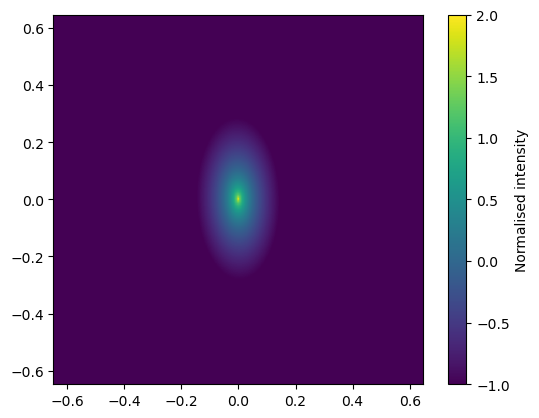

In [65]:
plt.imshow(np.log10(I_sersic), 
           origin='lower', 
           cmap='viridis',
           aspect='equal',
           interpolation='nearest', vmin=-1, vmax=2,
           extent=[x_arcsec.min(), x_arcsec.max(), y_arcsec.min(), y_arcsec.max()])
plt.colorbar(label='Normalised intensity')

In [66]:
print(f"Plate scale (demag): {plate_scale_demag} arcsec/m")

Plate scale (demag): 5182.598255886161 arcsec/m


In [67]:
125e-6 * plate_scale_demag

np.float64(0.6478247819857701)

In [68]:
20e-3 / plate_scale_demag

np.float64(3.859068176331226e-06)

In [69]:
def fft2c(field):
    """
    Centred, unitary forward 2-D FFT: pupil field -> fibre input plane.
    Transforms a 2D field from the pupil plane to the fibre input plane using a centred, 
    unitary forward 2-D FFT.
    """
    foward_fft = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(field), norm='ortho'))
    return foward_fft


def ifft2c(field):
    """
    Centred, unitary inverse 2-D FFT: fibre mode field -> pupil.
    Transforms a 2D field from the fibre input plane to the pupil plane using a centred,
    unitary inverse 2-D FFT.
    """
    inverse_fft = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(field), norm='ortho'))
    return inverse_fft


In [70]:
def linear_convolution_centred(E_source, E_psf):
    """
    Full linear complex-field convolution, cropped to the original
    FFT-centred grid. Explicit crop avoids the even-N 1-pixel 'same' offset.

    The complete linear convolution extends outside the returned grid.
    That finite-window loss is diagnosed independently below.
    """
    # assert means that the shapes of the source and PSF arrays must be the same; 
    # if not, an AssertionError will be raised.
    assert E_source.shape == E_psf.shape
    n_y, n_x = E_source.shape # dimensions of the source field
    # Convolve the source field with the PSF using FFT-based convolution. 
    full = fftconvolve(E_source, E_psf, mode='full') # note 'full' mode returns the complete convolution, which is larger than the original arrays
    # Crop the full convolution result to the original source field size, centered around the middle of the full array.
    cy, cx = n_y // 2, n_x // 2
    return full[cy:cy+n_y, cx:cx+n_x]

In [71]:
# # The exact PSF corresponding to the sampled VLT pupil mask.
# # Use the *complex amplitude* field, not an intensity PSF.
# E_psf_fft = fft2c(E_base_pupil)

In [72]:
E_psf_analytic, _ = diffraction_limited_E_field_at_fibre_2d(
    x, y, lam0, F_fibre, alpha=alpha_vlt, E_S=1.0, decentre=None
)
E_psf_analytic = np.asarray(E_psf_analytic, dtype=complex)
E_psf_analytic /= np.linalg.norm(E_psf_analytic)

Text(0, 0.5, 'E-field amplitude')

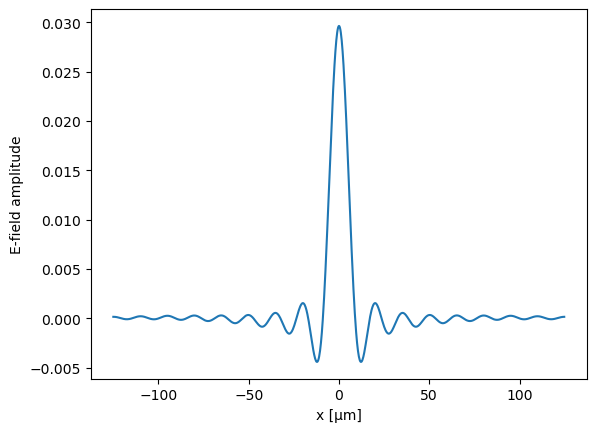

In [73]:
plt.plot(x_1d*1e6, E_psf_analytic[:, n_grid//2].real, label='PSF real part')
plt.xlabel('x [µm]')
plt.ylabel('E-field amplitude')

In [74]:
# Method 1 — focal-plane linear convolution, independent of QX/QY pupil construction.
E_focal_convolution = {
    name: linear_convolution_centred(S, E_psf_analytic)
    for name, S in E_source.items()
}

In [75]:
E_galaxy = E_focal_convolution['Sersic']

Text(0, 0.5, 'Y (arcsec)')

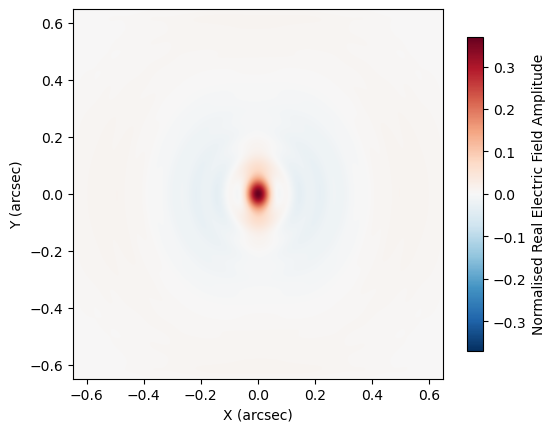

In [76]:
# Shared symmetric colour scale around zero.
vmax = np.max(np.abs(E_galaxy))
plt.imshow(E_galaxy.real, origin='lower', 
           cmap='RdBu_r', # red for positive, blue for negative
           aspect='equal',
           norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
           extent=(-angular_extent, angular_extent, -angular_extent, angular_extent))
plt.colorbar(
    shrink=0.85,
    label="Normalised Real Electric Field Amplitude"
)
plt.xlabel("X (arcsec)")
plt.ylabel("Y (arcsec)")


In [77]:
prepared_smf_mode_5p7micron

[{'l': 0,
  'm': 1,
  'cutoff_V': 0,
  'X_root': 1.6421672078395664,
  'Y_root': np.float64(1.7331965738385289),
  'angular': 'cos',
  'E_mode': array([[2.09733057e-24, 2.21431445e-24, 2.33769711e-24, ...,
          2.33769711e-24, 2.21431445e-24, 2.09733057e-24],
         [2.21431445e-24, 2.33795179e-24, 2.46835925e-24, ...,
          2.46835925e-24, 2.33795179e-24, 2.21431445e-24],
         [2.33769711e-24, 2.46835925e-24, 2.60618405e-24, ...,
          2.60618405e-24, 2.46835925e-24, 2.33769711e-24],
         ...,
         [2.33769711e-24, 2.46835925e-24, 2.60618405e-24, ...,
          2.60618405e-24, 2.46835925e-24, 2.33769711e-24],
         [2.21431445e-24, 2.33795179e-24, 2.46835925e-24, ...,
          2.46835925e-24, 2.33795179e-24, 2.21431445e-24],
         [2.09733057e-24, 2.21431445e-24, 2.33769711e-24, ...,
          2.33769711e-24, 2.21431445e-24, 2.09733057e-24]],
        shape=(1000, 1000)),
  'I_mode': array([[4.39879550e-48, 4.90318850e-48, 5.46482779e-48, ...,
        

In [78]:
LP01_5p7 = next(
    mode for mode in prepared_smf_mode_5p7micron
    if mode["l"] == 0
    and mode["m"] == 1
    and mode["angular"] == "cos"
)

E_5p7 = LP01_5p7["E_mode"]

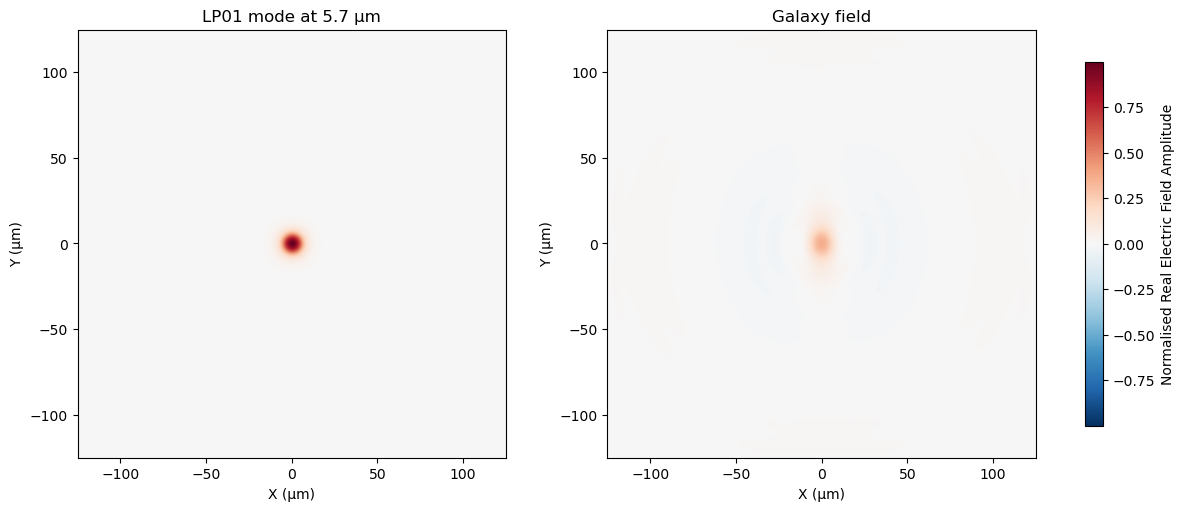

In [79]:
# Plot the fibre mode and galaxy field side by side.
extent = (
    x_1d.min() * 1e6,
    x_1d.max() * 1e6,
    y_1d.min() * 1e6,
    y_1d.max() * 1e6,
)

# Use one symmetric scale for both real parts.
vmax = max(
    np.max(np.abs(E_5p7.real)),
    np.max(np.abs(E_galaxy.real)),
)
norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

images = (
    (axes[0], E_5p7.real, "LP01 mode at 5.7 µm"),
    (axes[1], E_galaxy.real, "Galaxy field"),
)

for ax, field, title in images:
    image = ax.imshow(
        field,
        origin="lower",
        cmap="RdBu_r",
        aspect="equal",
        norm=norm,
        extent=extent,
    )
    ax.set_xlabel("X (µm)")
    ax.set_ylabel("Y (µm)")
    ax.set_title(title)

fig.colorbar(
    image,
    ax=axes,
    shrink=0.85,
    label="Normalised Real Electric Field Amplitude",
)
plt.show()

In [80]:
coupling_efficiency_2d(E_galaxy, E_5p7, x_1d, y_1d)[0]

np.float64(0.6557543726707564)

Text(0, 0.5, 'E-field amplitude')

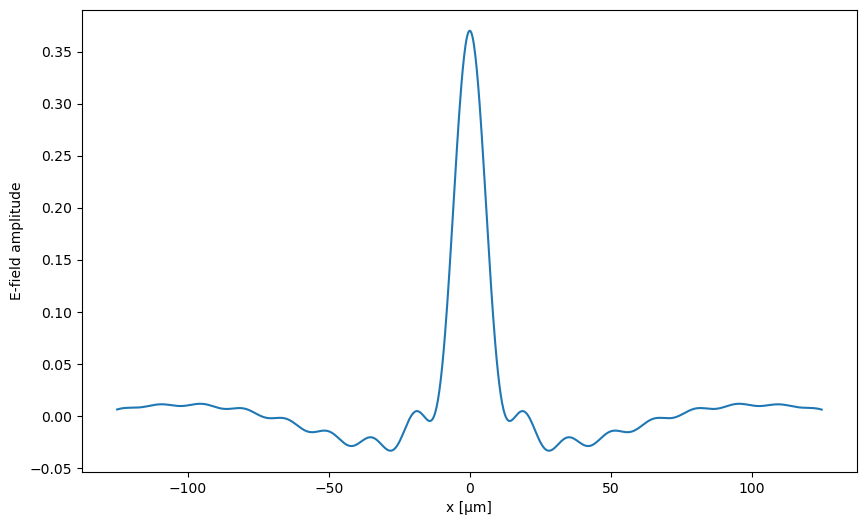

In [81]:
plt.figure(figsize=(10, 6))
plt.plot(x_1d*1e6, E_galaxy[n_grid//2, :].real, label='E-field real part')
plt.xlabel('x [μm]')
plt.ylabel('E-field amplitude')

In [82]:
delta_x_300, delta_y_300 = generate_jitter_positions(
    sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
    focal_length=f_coude,  # Focal length of the telescope in metres
    demagnification=Magnification,  # Demagnification factor
    n_samples=300,  # Number of random jitter positions
    rng=np.random.default_rng(seed=42)  # Random number generator with a fixed seed
)

In [83]:
I_galaxy = np.abs(E_galaxy)**2

In [84]:
# core_radius_test = np.array([29e-6])

# results_test = jittered_point_src_eta_per_mode_vs_core_radius(
#     core_radius_array=core_radius_test,
#     x=x,
#     y=y,
#     x_1d=x_1d,
#     y_1d=y_1d,
#     delta_x=delta_x_300,
#     delta_y=delta_y_300,
#     NA=NA,
#     lam0=lam0,
#     F_eff=F_fibre,
#     alpha=alpha_vlt,
#     E_S=1.0,
#     E_image=E_galaxy,
#     I_image=I_galaxy,
#     acceptance_radius="core_radius",
#     mode_case="few_mode",
#     az_sym=False,
#     fibre_offset_x=0.0,
#     fibre_offset_y=0.0,
# )

In [85]:
a_test = 29e-6

results_test = jittered_coherent_galaxy_eta_per_mode_vs_core_radius(
    core_radius_array=np.array([a_test]),

    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,

    E_galaxy=E_galaxy,

    delta_x=delta_x_300,
    delta_y=delta_y_300,

    NA=NA,
    lam0=lam0,

    acceptance_radius="two_cases_test",

    mode_case="few_mode",
    az_sym=False,

    fibre_offset_x=0.0,
    fibre_offset_y=0.0,

    n_jobs=1,
)

In [86]:
result_test = results_test[0]
result_test.keys()

dict_keys(['core_radius', 'no_mask', 'core_radius_mask', 'inside_core_radius'])

In [87]:
print("\nModes:")
print(result_test["no_mask"]["eta_mode_mean"].keys())


Modes:
dict_keys(['LP01', 'LP11 cos', 'LP11 sin', 'LP02', 'LP21 cos', 'LP21 sin', 'LP31 cos', 'LP31 sin', 'LP12 cos', 'LP12 sin', 'LP41 cos', 'LP41 sin', 'LP03', 'LP22 cos', 'LP22 sin', 'LP51 cos', 'LP51 sin', 'LP32 cos', 'LP32 sin', 'LP13 cos', 'LP13 sin', 'LP61 cos', 'LP61 sin', 'LP42 cos', 'LP42 sin', 'LP71 cos', 'LP71 sin', 'LP04', 'LP23 cos', 'LP23 sin', 'LP52 cos', 'LP52 sin', 'LP81 cos', 'LP81 sin', 'LP33 cos', 'LP33 sin', 'LP14 cos', 'LP14 sin'])


In [88]:
for mode_label, eta_mean in result_test["no_mask"]["eta_mode_mean"].items():
    print(
        f"{mode_label}: "
        f"mean eta = {eta_mean:.6f}"
    )

LP01: mean eta = 0.354076
LP11 cos: mean eta = 0.054345
LP11 sin: mean eta = 0.025597
LP02: mean eta = 0.186677
LP21 cos: mean eta = 0.050994
LP21 sin: mean eta = 0.002891
LP31 cos: mean eta = 0.004623
LP31 sin: mean eta = 0.002124
LP12 cos: mean eta = 0.027227
LP12 sin: mean eta = 0.011096
LP41 cos: mean eta = 0.002274
LP41 sin: mean eta = 0.000423
LP03: mean eta = 0.019916
LP22 cos: mean eta = 0.005799
LP22 sin: mean eta = 0.002941
LP51 cos: mean eta = 0.000403
LP51 sin: mean eta = 0.000217
LP32 cos: mean eta = 0.001764
LP32 sin: mean eta = 0.001304
LP13 cos: mean eta = 0.019980
LP13 sin: mean eta = 0.008137
LP61 cos: mean eta = 0.000155
LP61 sin: mean eta = 0.000059
LP42 cos: mean eta = 0.000514
LP42 sin: mean eta = 0.000384
LP71 cos: mean eta = 0.000033
LP71 sin: mean eta = 0.000022
LP04: mean eta = 0.021965
LP23 cos: mean eta = 0.011230
LP23 sin: mean eta = 0.002597
LP52 cos: mean eta = 0.000096
LP52 sin: mean eta = 0.000077
LP81 cos: mean eta = 0.000009
LP81 sin: mean eta = 0.000

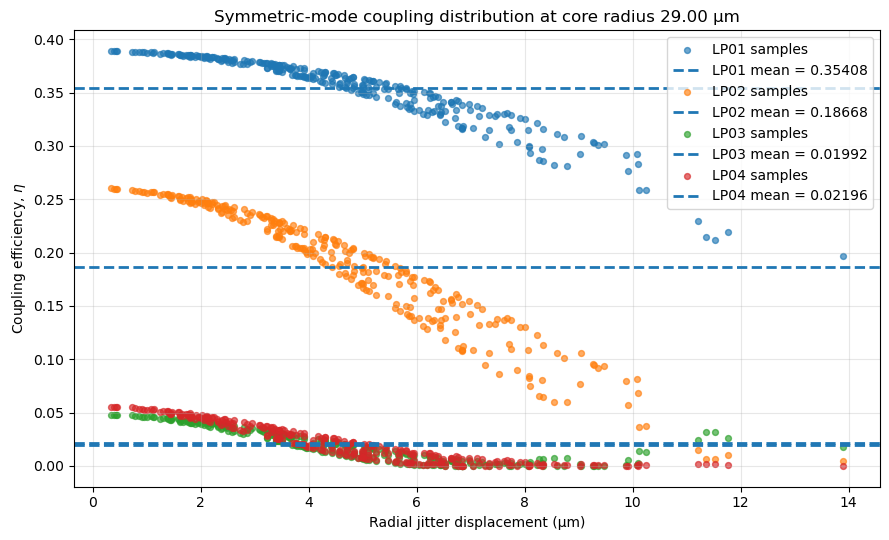

In [89]:
# Radial magnitude of every jitter displacement
jitter_displacement_um = (
    np.hypot(delta_x_300, delta_y_300) * 1e6
)

# Extract the symmetric modes only: LP01, LP02, LP03, ...
symmetric_mode_samples = {
    mode_label: eta_samples
    for mode_label, eta_samples
    in result_test["no_mask"]["eta_mode_samples"].items()
    if mode_label.startswith("LP0")
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for mode_label, eta_samples in symmetric_mode_samples.items():

    eta_mean = np.mean(eta_samples)

    ax.scatter(
        jitter_displacement_um,
        eta_samples,
        s=18,
        alpha=0.65,
        label=rf"{mode_label} samples",
    )

    ax.axhline(
        eta_mean,
        linestyle="--",
        linewidth=2,
        label=rf"{mode_label} mean = {eta_mean:.5f}",
    )

ax.set_xlabel("Radial jitter displacement (µm)")
ax.set_ylabel(r"Coupling efficiency, $\eta$")
ax.set_title(
    rf"Symmetric-mode coupling distribution "
    rf"at core radius {a_test * 1e6:.2f} µm"
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [90]:
r_max_large = 150e-6

x_large, y_large, x_large_1d, y_large_1d = (
    make_larger_image_grid(
        x_1d=x_1d,
        y_1d=y_1d,
        r_max_large=r_max_large
    )
)

In [91]:
x_large_arcsec = (
    x_large
    * plate_scale_demag
)

y_large_arcsec = (
    y_large
    * plate_scale_demag
)

In [92]:
I_sersic_large = model_cent(
    x_large_arcsec,
    y_large_arcsec
)

In [93]:
I_sersic_large = normalise_intensity(
    I_sersic_large
)

E_source_sersic_large = (
    np.sqrt(
        I_sersic_large
    ).astype(complex)
)

In [94]:
E_psf_large, _ = (
    diffraction_limited_E_field_at_fibre_2d(
        x_large,
        y_large,
        lam0,
        F_fibre,
        alpha=alpha_vlt,
        E_S=1.0,
        decentre=None
    )
)

E_psf_large = np.asarray(
    E_psf_large,
    dtype=complex
)

E_psf_large /= np.linalg.norm(
    E_psf_large
)

In [95]:
E_galaxy_large = linear_convolution_centred(
    E_source_sersic_large,
    E_psf_large
)

In [96]:
E_interpolator = make_E_image_interpolator(
    E_image=E_galaxy_large,
    x_image_1d=x_large_1d,
    y_image_1d=y_large_1d
)

In [97]:
a_test = 29e-6

results_test_large = jittered_coherent_galaxy_eta_per_mode_vs_core_radius(
    core_radius_array=np.array([a_test]),

    # Fixed fibre-overlap grid:
    # 1000 x 1000, approximately ±125 µm
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,

    # Coherent galaxy calculated on the larger grid:
    E_galaxy=E_galaxy_large,
    x_E_image_1d=x_large_1d,
    y_E_image_1d=y_large_1d,

    delta_x=delta_x_300,
    delta_y=delta_y_300,

    NA=NA,
    lam0=lam0,

    acceptance_radius="two_cases_test",

    mode_case="few_mode",
    az_sym=False,

    fibre_offset_x=0.0,
    fibre_offset_y=0.0,

    n_jobs=1,
)

In [99]:
result_test_large = results_test_large[0]

print(
    "Original grid, no mask:",
    result_test["no_mask"]["eta_total_mean"]
)

print(
    "Large grid, no mask:",
    result_test_large["no_mask"]["eta_total_mean"]
)

print(
    "Original grid, core mask:",
    result_test["core_radius_mask"]["eta_total_mean"]
)

print(
    "Large grid, core mask:",
    result_test_large["core_radius_mask"]["eta_total_mean"]
)

Original grid, no mask: 0.8258514802152672
Large grid, no mask: 0.8546979059782992
Original grid, core mask: 0.8258514802152672
Large grid, core mask: 0.8546979059782992


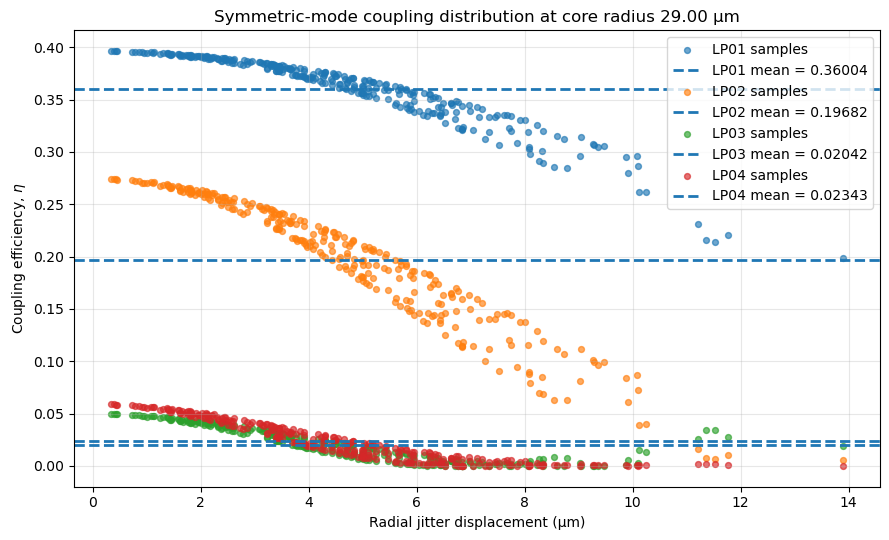

In [100]:
# Radial magnitude of every jitter displacement
jitter_displacement_um = (
    np.hypot(delta_x_300, delta_y_300) * 1e6
)

# Extract the symmetric modes only: LP01, LP02, LP03, ...
symmetric_mode_samples = {
    mode_label: eta_samples
    for mode_label, eta_samples
    in result_test_large["no_mask"]["eta_mode_samples"].items()
    if mode_label.startswith("LP0")
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for mode_label, eta_samples in symmetric_mode_samples.items():

    eta_mean = np.mean(eta_samples)

    ax.scatter(
        jitter_displacement_um,
        eta_samples,
        s=18,
        alpha=0.65,
        label=rf"{mode_label} samples",
    )

    ax.axhline(
        eta_mean,
        linestyle="--",
        linewidth=2,
        label=rf"{mode_label} mean = {eta_mean:.5f}",
    )

ax.set_xlabel("Radial jitter displacement (µm)")
ax.set_ylabel(r"Coupling efficiency, $\eta$")
ax.set_title(
    rf"Symmetric-mode coupling distribution "
    rf"at core radius {a_test * 1e6:.2f} µm"
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [101]:
print(
    "No-mask difference:",
    result_test_large["no_mask"]["eta_total_mean"]
    - result_test["no_mask"]["eta_total_mean"]
)

print(
    "Core-mask difference:",
    result_test_large["core_radius_mask"]["eta_total_mean"]
    - result_test["core_radius_mask"]["eta_total_mean"]
)

No-mask difference: 0.02884642576303198
Core-mask difference: 0.02884642576303198


In [102]:
a_test = 5.7e-6

results_test = jittered_coherent_galaxy_eta_per_mode_vs_core_radius(
    core_radius_array=np.array([a_test]),

    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,

    E_galaxy=E_galaxy,

    delta_x=delta_x_300,
    delta_y=delta_y_300,

    NA=NA,
    lam0=lam0,

    acceptance_radius="two_cases_test",

    mode_case="few_mode",
    az_sym=False,

    fibre_offset_x=0.0,
    fibre_offset_y=0.0,

    n_jobs=1,
)

results_test_large = jittered_coherent_galaxy_eta_per_mode_vs_core_radius(
    core_radius_array=np.array([a_test]),

    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,

    E_galaxy=E_galaxy_large,
    x_E_image_1d=x_large_1d,
    y_E_image_1d=y_large_1d,

    delta_x=delta_x_300,
    delta_y=delta_y_300,

    NA=NA,
    lam0=lam0,

    acceptance_radius="two_cases_test",

    mode_case="few_mode",
    az_sym=False,

    fibre_offset_x=0.0,
    fibre_offset_y=0.0,

    n_jobs=1,
)

In [103]:
result_test = results_test[0]
result_test_large = results_test_large[0]

In [104]:
print(
    "Original grid, no mask:",
    result_test["no_mask"]["eta_total_mean"]
)

print(
    "Large grid, no mask:",
    result_test_large["no_mask"]["eta_total_mean"]
)

print(
    "Original grid, core mask:",
    result_test["core_radius_mask"]["eta_total_mean"]
)

print(
    "Large grid, core mask:",
    result_test_large["core_radius_mask"]["eta_total_mean"]
)


Original grid, no mask: 0.4484932774486155
Large grid, no mask: 0.46359510535358517
Original grid, core mask: 0.35708761402366257
Large grid, core mask: 0.3694382132904022


In [105]:
inside_core = result_test_large["inside_core_radius"]

print("Inside core:", np.sum(inside_core))
print("Outside core:", np.sum(~inside_core))
print("Total samples:", len(inside_core))

print(
    "Maximum jitter radius:",
    np.max(
        np.hypot(delta_x_300, delta_y_300)
    ) * 1e6,
    "µm"
)

Inside core: 201
Outside core: 99
Total samples: 300
Maximum jitter radius: 13.902610091693973 µm


In [106]:
eta_original = result_test["no_mask"]["eta_total_samples"]
eta_large = result_test_large["no_mask"]["eta_total_samples"]

difference = eta_large - eta_original

print("Mean difference:", np.mean(difference))
print("Minimum difference:", np.min(difference))
print("Maximum difference:", np.max(difference))

Mean difference: 0.015101827904969676
Minimum difference: 0.00023197605252291142
Maximum difference: 0.023630222648338917


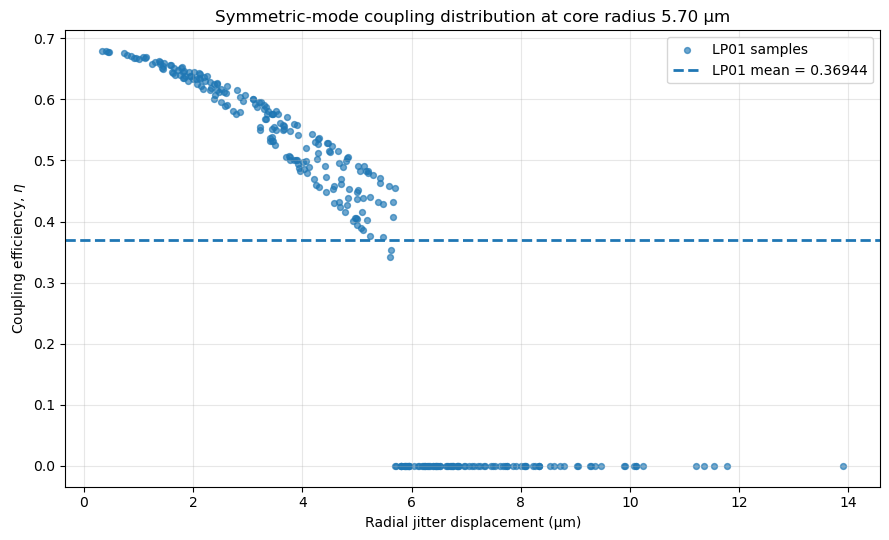

In [109]:
# Radial magnitude of every jitter displacement
jitter_displacement_um = (
    np.hypot(delta_x_300, delta_y_300) * 1e6
)

# Extract the symmetric modes only: LP01, LP02, LP03, ...
symmetric_mode_samples = {
    mode_label: eta_samples
    for mode_label, eta_samples
    in result_test_large["core_radius_mask"]["eta_mode_samples"].items()
    if mode_label.startswith("LP0")
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for mode_label, eta_samples in symmetric_mode_samples.items():

    eta_mean = np.mean(eta_samples)

    ax.scatter(
        jitter_displacement_um,
        eta_samples,
        s=18,
        alpha=0.65,
        label=rf"{mode_label} samples",
    )

    ax.axhline(
        eta_mean,
        linestyle="--",
        linewidth=2,
        label=rf"{mode_label} mean = {eta_mean:.5f}",
    )

ax.set_xlabel("Radial jitter displacement (µm)")
ax.set_ylabel(r"Coupling efficiency, $\eta$")
ax.set_title(
    rf"Symmetric-mode coupling distribution "
    rf"at core radius {a_test * 1e6:.2f} µm"
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [110]:
results_jitter_per_mode_full = jittered_coherent_galaxy_eta_per_mode_vs_core_radius(
    core_radius_array=core_radius_range_full,

    # Fixed fibre-overlap grid
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,

    # Larger coherent galaxy field
    E_galaxy=E_galaxy_large,
    x_E_image_1d=x_large_1d,
    y_E_image_1d=y_large_1d,

    # Jitter samples
    delta_x=delta_x_300,
    delta_y=delta_y_300,

    NA=NA,
    lam0=lam0,

    acceptance_radius="two_cases_test",

    mode_case="few_mode",
    az_sym=False,

    fibre_offset_x=0.0,
    fibre_offset_y=0.0,

    n_jobs=4,
)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  1.5min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  2.2min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  4.0min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  4.9min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  7.3min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed: 10.8min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed: 14.5min
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed: 18.1min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed: 24.5min
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed: 30.9min
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed: 38.5min
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed: 47.2min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed: 57.5min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed: 69.3min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed: 84.6min
[Para

In [115]:
from pathlib import Path
import joblib


# ---------------------------------------------------------
# Use existing checkpoint directory
# ---------------------------------------------------------
checkpoint_dir = Path(
    "/Users/tliu/oh_suppression/result/Coherent_galaxy_jitter_per_mode"
)


# ---------------------------------------------------------
# Define new checkpoint file
# ---------------------------------------------------------
checkpoint_file = (
    checkpoint_dir /
    "results_coherent_galaxy_jitter_per_mode_two_cases_large_grid.joblib"
)


# ---------------------------------------------------------
# Save results and calculation parameters
# ---------------------------------------------------------
checkpoint = {
    # Main results
    "results_jitter_per_mode_full":
        results_jitter_per_mode_full,

    # Fibre core radius range
    "core_radius_array":
        core_radius_range_full,

    # Monte Carlo jitter positions
    "delta_x":
        delta_x_300,

    "delta_y":
        delta_y_300,

    # Optical parameters
    "NA":
        NA,

    "lam0":
        lam0,

    "F_eff":
        F_fibre,

    "alpha":
        alpha_vlt,

    "E_S":
        1.0,

    # Coupling model settings
    "acceptance_radius":
        "two_cases_test",

    "mode_case":
        "few_mode",

    "az_sym":
        False,

    # Fixed fibre alignment
    "fibre_offset_x":
        0.0,

    "fibre_offset_y":
        0.0,

    # Larger coherent-galaxy electric-field grid
    "x_E_image_1d":
        x_large_1d,

    "y_E_image_1d":
        y_large_1d,

    "r_max_E_image":
        r_max_large,

    # Fixed fibre-overlap grid
    "x_1d":
        x_1d,

    "y_1d":
        y_1d,

    # Monte Carlo information
    "n_jitter_samples":
        len(delta_x_300),
}


joblib.dump(
    checkpoint,
    checkpoint_file
)

print(
    f"Checkpoint saved to:\n{checkpoint_file}"
)

Checkpoint saved to:
/Users/tliu/oh_suppression/result/Coherent_galaxy_jitter_per_mode/results_coherent_galaxy_jitter_per_mode_two_cases_large_grid.joblib


In [116]:
checkpoint = joblib.load(checkpoint_file)

results_jitter_per_mode_full = (
    checkpoint["results_jitter_per_mode_full"]
)

core_radius_range_full = checkpoint["core_radius_array"]

delta_x_300 = checkpoint["delta_x"]
delta_y_300 = checkpoint["delta_y"]

print(
    f"Loaded {len(results_jitter_per_mode_full)} "
    f"core-radius results."
)

Loaded 276 core-radius results.


In [246]:
# del checkpoint
gc.collect()

48513

In [117]:
array_size = 0

for result in results_jitter_per_mode_full:

    for case in ["no_mask", "core_radius_mask"]:

        case_result = result[case]

        array_size += (
            case_result["eta_total_samples"].nbytes
        )

        for eta_samples in (
            case_result["eta_mode_samples"].values()
        ):
            array_size += eta_samples.nbytes

    array_size += (
        result["inside_core_radius"].nbytes
    )

In [118]:
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0

def V_to_radius_um(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6


In [240]:
def plot_jittered_coherent_galaxy_asymmetric_modes(
    core_radius_array,
    results,
    result_case="no_mask",
    title="Jitter-averaged point-source coupling efficiency of asymmetric LP modes",
):
    """
    Plot total jitter-averaged coupling efficiency
    and asymmetric LP modes only.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii.

    results : list
        Results returned by
        jittered_coherent_galaxy_eta_per_mode_vs_core_radius().

    result_case : {"no_mask", "core_radius_mask"}
        Which returned coupling case to plot.

    Asymmetric modes are identified from labels containing:
        " cos"
        " sin"

    The cos/sin pair for each base LP mode shares the same colour.
    """

    if result_case not in ["no_mask", "core_radius_mask"]:
        raise ValueError(
            "result_case must be 'no_mask' or 'core_radius_mask'."
        )

    # Extract the total jitter-averaged coupling efficiency.
    eta_total_mean = np.array([
        result[result_case]["eta_total_mean"]
        for result in results
    ])

    # Find all mode labels present in the results.
    all_mode_labels = sorted(
        set(
            mode_label
            for result in results
            for mode_label in result[result_case]["eta_mode_mean"].keys()
        )
    )

    # Keep only asymmetric modes.
    asymmetric_mode_labels = [
        label
        for label in all_mode_labels
        if (" cos" in label) or (" sin" in label)
    ]

    # Store the coupling efficiency of each asymmetric mode
    # as a function of fibre core radius.
    asymmetric_mode_eta_dict = {}

    for mode_label in asymmetric_mode_labels:
        asymmetric_mode_eta_dict[mode_label] = np.array([
            result[result_case]["eta_mode_mean"].get(mode_label, 0.0)
            for result in results
        ])

    # Base mode names: LP11, LP21, LP31, ...
    base_modes = sorted(
        set(
            label.split()[0]
            for label in asymmetric_mode_eta_dict.keys()
        )
    )

    # One colour per base LP mode.
    cmap = plt.cm.turbo
    colours = cmap(
        np.linspace(0, 1, len(base_modes))
    )

    colour_dict = {
        base_mode: colours[i]
        for i, base_mode in enumerate(base_modes)
    }

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total jitter-averaged coupling efficiency.
    ax1.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color="black",
        linewidth=2,
        label=r"Total $\eta$"
    )

    # Shade single-mode region.
    V_1_2 = 1.2
    V_2_405 = 2.405

    ax1.axvspan(
        V_to_radius_um(V_1_2),
        V_to_radius_um(V_2_405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # Plot asymmetric modes.
    mode_lines = {}

    for base_mode in base_modes:

        cos_label = f"{base_mode} cos"
        sin_label = f"{base_mode} sin"

        colour = colour_dict[base_mode]

        if cos_label in asymmetric_mode_eta_dict:
            line_cos, = ax1.plot(
                core_radius_array * 1e6,
                asymmetric_mode_eta_dict[cos_label],
                linestyle="dashed",
                linewidth=1.5,
                alpha=0.9,
                color=colour,
                label=cos_label
            )

            mode_lines[cos_label] = line_cos

        if sin_label in asymmetric_mode_eta_dict:
            line_sin, = ax1.plot(
                core_radius_array * 1e6,
                asymmetric_mode_eta_dict[sin_label],
                linestyle="dotted",
                linewidth=1.8,
                alpha=0.9,
                color=colour,
                label=sin_label
            )

            mode_lines[sin_label] = line_sin

    # Axis labels.
    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=16,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Jitter-averaged coupling efficiency, $\eta$",
        fontsize=16,
        labelpad=8
    )

    # ax1.set_title(title, fontsize=15)

    ax1.tick_params(axis="x", labelsize=14)
    ax1.tick_params(axis="y", labelsize=14)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top x-axis: normalised frequency V.
    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um)
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(axis="x", labelsize=14)
    ax_top.minorticks_on()

    # Legend.
    handles, labels = ax1.get_legend_handles_labels()

    ax1.legend(
        handles,
        labels,
        loc="center right",
        bbox_to_anchor=(0.98, 0.5),
        bbox_transform=ax1.transAxes,
        ncol=3,
        fontsize=8,
        frameon=True,
        columnspacing=0.8,
        handlelength=1.6,
        handletextpad=0.4,
        borderaxespad=0.4
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    return asymmetric_mode_eta_dict, mode_lines

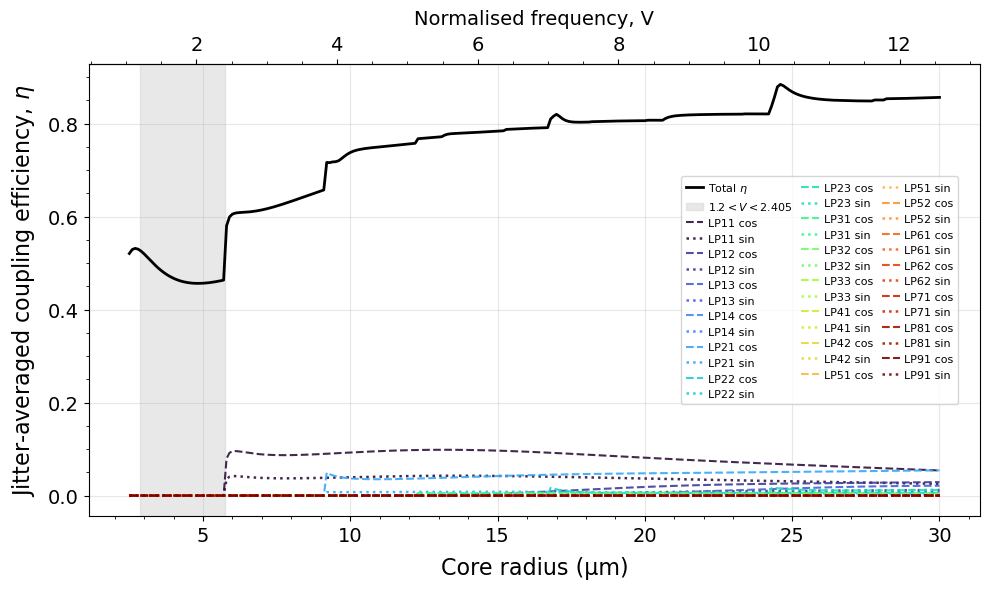

In [241]:
asymmetric_mode_eta_dict, mode_lines = (
    plot_jittered_coherent_galaxy_asymmetric_modes(
        core_radius_array=core_radius_range_full,
        results=results_jitter_per_mode_full,
        result_case="no_mask",
    )
)

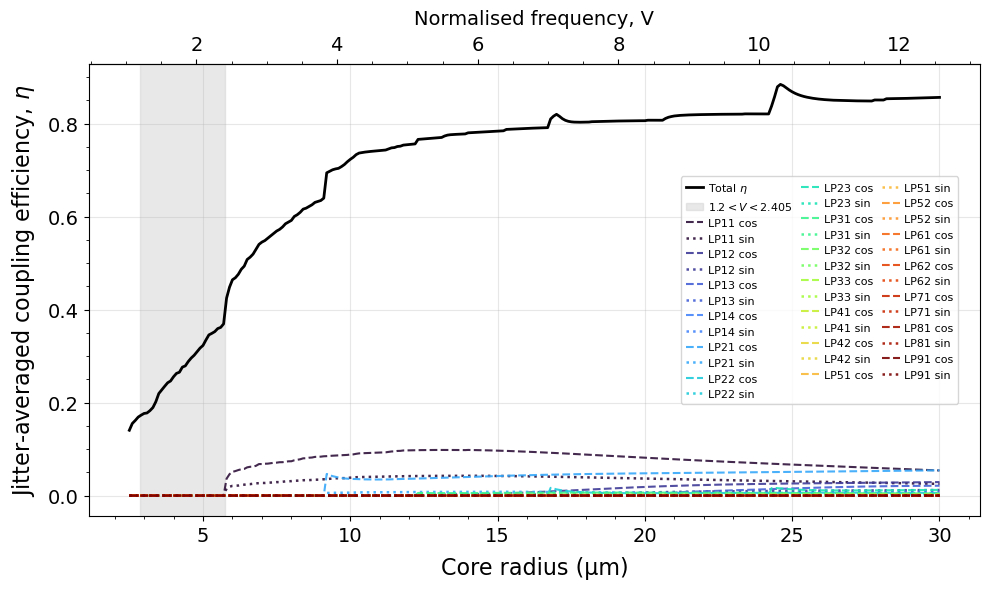

In [242]:
asymmetric_mode_eta_dict, mode_lines = (
    plot_jittered_coherent_galaxy_asymmetric_modes(
        core_radius_array=core_radius_range_full,
        results=results_jitter_per_mode_full,
        result_case="core_radius_mask",
    )
)

In [234]:
def plot_jittered_coherent_galaxy_symmetric_modes(
    core_radius_array,
    results,
    result_case="no_mask",
    title="Jitter-averaged coherent-galaxy coupling efficiency of symmetric LP modes",
):
    """
    Plot total jitter-averaged coupling efficiency
    and symmetric LP modes only.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii.

    results : list
        Results returned by
        jittered_coherent_galaxy_eta_per_mode_vs_core_radius().

    result_case : {"no_mask", "core_radius_mask"}
        Which returned coupling case to plot.

    Symmetric modes are identified as:
        LP01, LP02, LP03, ...
    """

    if result_case not in ["no_mask", "core_radius_mask"]:
        raise ValueError(
            "result_case must be 'no_mask' or 'core_radius_mask'."
        )

    # Extract the total jitter-averaged coupling efficiency.
    eta_total_mean = np.array([
        result[result_case]["eta_total_mean"]
        for result in results
    ])

    # Find all mode labels present in the results.
    all_mode_labels = sorted(
        set(
            mode_label
            for result in results
            for mode_label in result[result_case]["eta_mode_mean"].keys()
        )
    )

    # Keep only symmetric modes: LP01, LP02, LP03, ...
    symmetric_mode_labels = [
        label
        for label in all_mode_labels
        if label.startswith("LP0")
    ]

    # Store the coupling efficiency of each symmetric mode
    # as a function of fibre core radius.
    symmetric_mode_eta_dict = {}

    for mode_label in symmetric_mode_labels:
        symmetric_mode_eta_dict[mode_label] = np.array([
            result[result_case]["eta_mode_mean"].get(mode_label, 0.0)
            for result in results
        ])

    # One colour per l=0 LP mode.
    mode_colours = [
        "tab:blue",    # LP01
        "tab:orange",  # LP02
        "tab:green",   # LP03
        "tab:red",     # LP04
    ]

    # One line style per l=0 LP mode.
    linestyles = [
        "--",   # LP01: dashed
        "-.",   # LP02: dash-dot
        ":",    # LP03: dotted
        "-",    # LP04: solid
    ]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total jitter-averaged coupling efficiency.
    ax1.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color="black",
        linewidth=2,
        label=r"Total jitter-averaged coupling efficiency, $\eta$"
    )

    # Shade single-mode region.
    V_1_2 = 1.2
    V_2_405 = 2.405

    ax1.axvspan(
        V_to_radius_um(V_1_2),
        V_to_radius_um(V_2_405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # Plot symmetric modes.
    mode_lines = {}

    for i, mode_label in enumerate(symmetric_mode_labels):

        line, = ax1.plot(
            core_radius_array * 1e6,
            symmetric_mode_eta_dict[mode_label],
            linestyle=linestyles[i],
            linewidth=1.8,
            alpha=0.9,
            color=mode_colours[i],
            label=mode_label
        )

        mode_lines[mode_label] = line

    # Axis labels.
    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=16,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Jitter-averaged coupling efficiency, $\eta$",
        fontsize=16,
        labelpad=8
    )

    # ax1.set_title(title, fontsize=15)

    ax1.tick_params(axis="x", labelsize=14)
    ax1.tick_params(axis="y", labelsize=14)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top x-axis: normalised frequency V.
    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um)
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(axis="x", labelsize=14)
    ax_top.minorticks_on()

    # Legend: inside the plot, right side, middle height.
    handles, labels = ax1.get_legend_handles_labels()

    ax1.legend(
        handles,
        labels,
        loc="center right",
        bbox_to_anchor=(0.98, 0.5),
        bbox_transform=ax1.transAxes,
        ncol=3,
        fontsize=8,
        frameon=True,
        columnspacing=0.8,
        handlelength=1.6,
        handletextpad=0.4,
        borderaxespad=0.4
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    return symmetric_mode_eta_dict, mode_lines

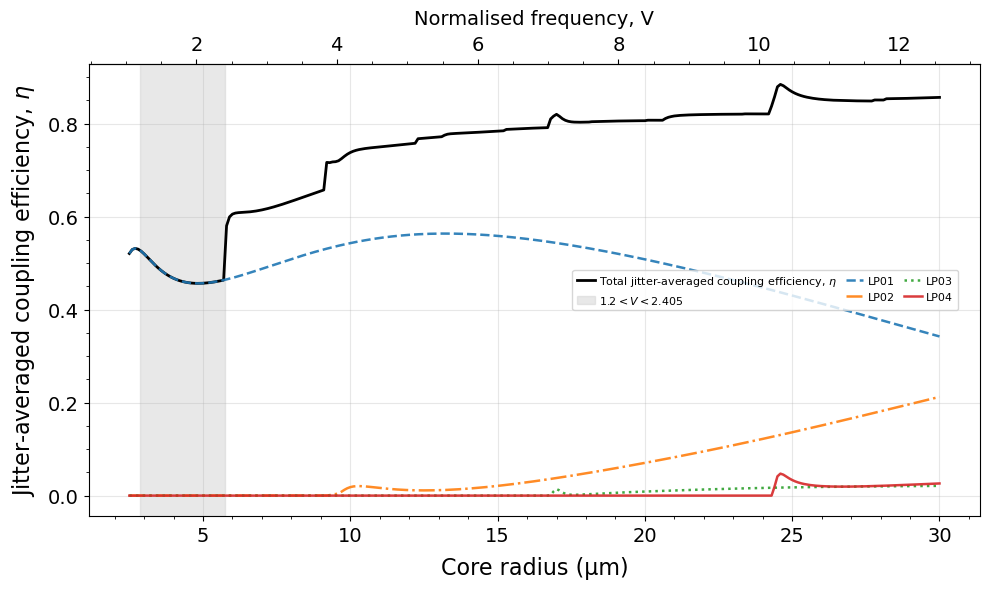

In [235]:
symmetric_mode_eta_dict, mode_lines = (
    plot_jittered_coherent_galaxy_symmetric_modes(
        core_radius_array=core_radius_range_full,
        results=results_jitter_per_mode_full,
        result_case="no_mask",
    )
)

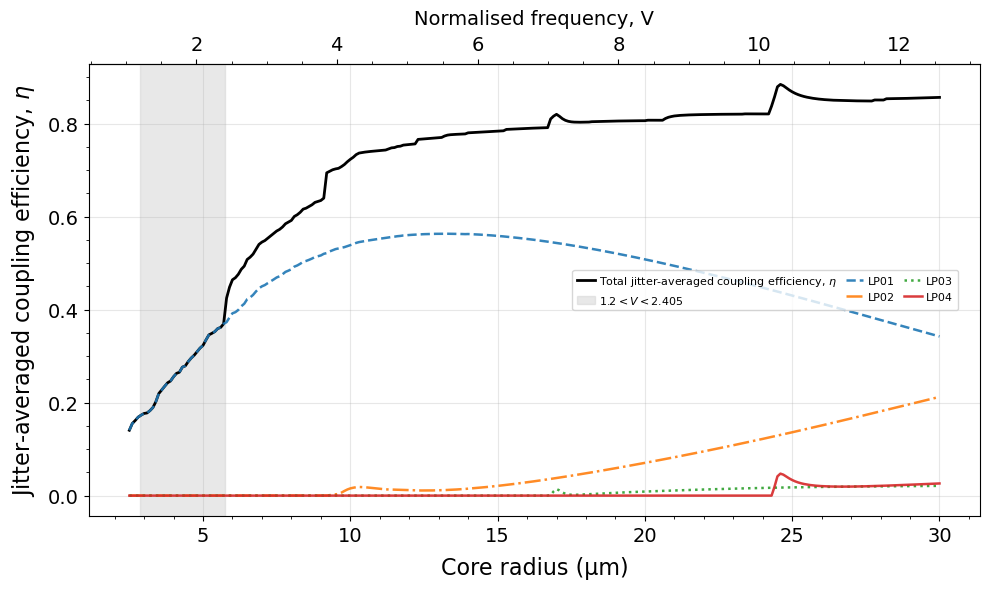

In [236]:
symmetric_mode_eta_dict, mode_lines = (
    plot_jittered_coherent_galaxy_symmetric_modes(
        core_radius_array=core_radius_range_full,
        results=results_jitter_per_mode_full,
        result_case="core_radius_mask",
    )
)

In [237]:
def plot_jittered_coherent_galaxy_lp_mode_families(
    core_radius_array,
    results,
    lam0,
    NA,
    result_case="no_mask",
    source_name="Sérsic",
):
    """
    Plot total jitter-averaged coherent-galaxy coupling efficiency
    and individual LP mode-family contributions.

    Cosine and sine components of asymmetric LP modes are combined
    into the same LP mode family.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii [m].

    results : list
        Results returned by
        jittered_coherent_galaxy_eta_per_mode_vs_core_radius().

    lam0 : float
        Wavelength [m].

    NA : float
        Fibre numerical aperture.

    result_case : {"no_mask", "core_radius_mask"}
        Which returned coupling case to plot.

    source_name : str
        Name of the source, e.g. "Sérsic".

    Returns
    -------
    families : dict
        LP mode-family coupling efficiency arrays.
    """

    if result_case not in ["no_mask", "core_radius_mask"]:
        raise ValueError(
            "result_case must be 'no_mask' or 'core_radius_mask'."
        )

    # ========================================================
    # 1. Extract total jitter-averaged coupling efficiency
    # ========================================================

    eta_total_mean = np.array([
        result[result_case]["eta_total_mean"]
        for result in results
    ])

    # ========================================================
    # 2. Find all mode labels present in the results
    # ========================================================

    all_mode_labels = sorted(
        set(
            mode_label
            for result in results
            for mode_label in result[result_case]["eta_mode_mean"].keys()
        )
    )

    # ========================================================
    # 3. Determine LP mode families
    # ========================================================

    family_names = sorted(
        set(
            label.split()[0]
            for label in all_mode_labels
        )
    )

    families = {}

    for family_name in family_names:

        # Symmetric mode, e.g. LP01, LP02, ...
        if family_name.startswith("LP0"):

            families[family_name] = np.array([
                result[result_case]["eta_mode_mean"].get(
                    family_name,
                    0.0
                )
                for result in results
            ])

        # Asymmetric mode family, e.g. LP11 = LP11 cos + LP11 sin
        else:

            cos_label = f"{family_name} cos"
            sin_label = f"{family_name} sin"

            eta_cos = np.array([
                result[result_case]["eta_mode_mean"].get(
                    cos_label,
                    0.0
                )
                for result in results
            ])

            eta_sin = np.array([
                result[result_case]["eta_mode_mean"].get(
                    sin_label,
                    0.0
                )
                for result in results
            ])

            families[family_name] = (
                eta_cos
                + eta_sin
            )

    # ========================================================
    # 4. Sort mode families by first non-zero contribution
    # ========================================================

    names = sorted(
        families,
        key=lambda name: np.where(
            families[name] > 0
        )[0][0]
        if np.any(families[name] > 0)
        else len(core_radius_array)
    )

    # ========================================================
    # 5. Assign colours and line styles
    # ========================================================

    colours = plt.cm.turbo(
        np.linspace(
            0,
            1,
            max(len(names), 1)
        )
    )

    styles = [
        "--",
        ":",
        "-.",
        (0, (5, 2)),
        (0, (3, 1, 1, 1)),
        (0, (1, 1))
    ]

    # ========================================================
    # 6. Plot total and LP mode-family efficiencies
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(11, 6)
    )

    # Total jitter-averaged coherent coupling efficiency.
    ax.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color="black",
        lw=2.4,
        label=(
            f"Total jitter-averaged "
            f"{source_name} coupling"
        )
    )

    # Individual LP mode families.
    for i, name in enumerate(names):

        ax.plot(
            core_radius_array * 1e6,
            families[name],
            color=colours[i],
            lw=1.8,
            ls=styles[
                i % len(styles)
            ],
            label=name
        )

    # ========================================================
    # 7. Shade the single-mode region
    # ========================================================

    ax.axvspan(
        1.2 * lam0 / (2 * np.pi * NA) * 1e6,
        2.405 * lam0 / (2 * np.pi * NA) * 1e6,
        color="lightgrey",
        alpha=0.4,
        label=r"$1.2 < V < 2.405$"
    )

    # ========================================================
    # 8. Axis formatting
    # ========================================================

    ax.set_xlabel(
        "Fibre core radius (µm)",
        fontsize=16
    )

    ax.set_ylabel(
        rf"Jitter-averaged coherent {source_name} coupling efficiency",
        fontsize=16
    )

    ax.tick_params(
        axis="x",
        labelsize=14
    )

    ax.tick_params(
        axis="y",
        labelsize=14
    )

    ax.grid(
        alpha=0.3
    )

    ax.minorticks_on()

    # ========================================================
    # 9. Legend
    # ========================================================

    ax.legend(
        ncol=3,
        fontsize=8,
        loc="center right",
        bbox_to_anchor=(0.98, 0.5),
        frameon=True
    )

    # ========================================================
    # 10. Secondary x-axis: V-number
    # ========================================================

    ax_top = ax.secondary_xaxis(
        "top",
        functions=(
            lambda radius_um:
                2 * np.pi
                * radius_um
                * 1e-6
                * NA
                / lam0,

            lambda V:
                V
                * lam0
                / (2 * np.pi * NA)
                * 1e6
        )
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14
    )

    ax_top.tick_params(
        axis="x",
        labelsize=14
    )

    ax_top.minorticks_on()

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    return families

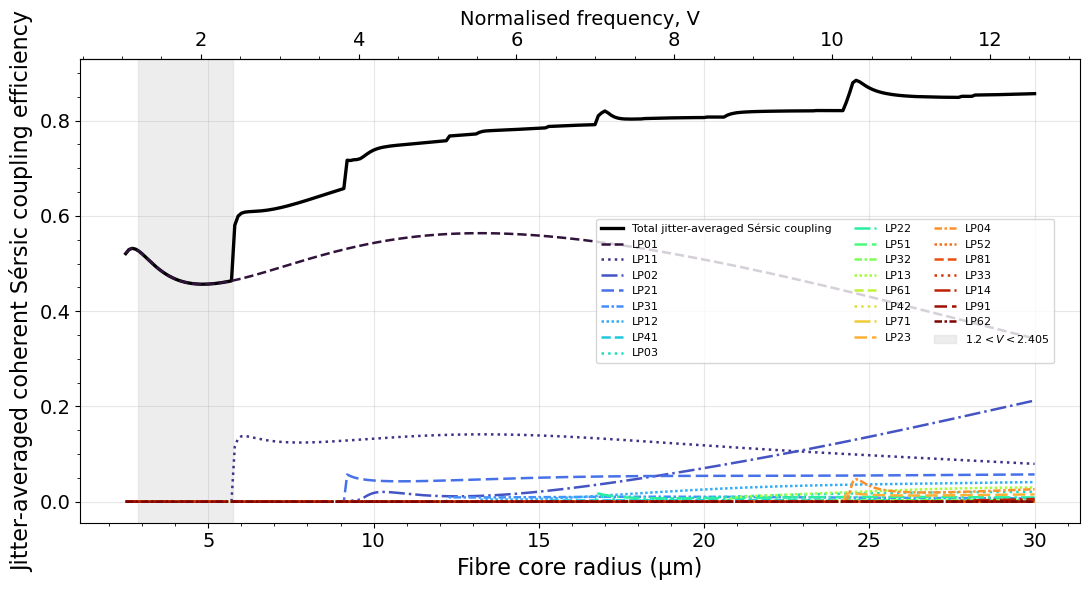

In [238]:
families_no_mask = plot_jittered_coherent_galaxy_lp_mode_families(
    core_radius_array=core_radius_range_full,
    results=results_jitter_per_mode_full,
    lam0=lam0,
    NA=NA,
    result_case="no_mask",
    source_name="Sérsic",
)

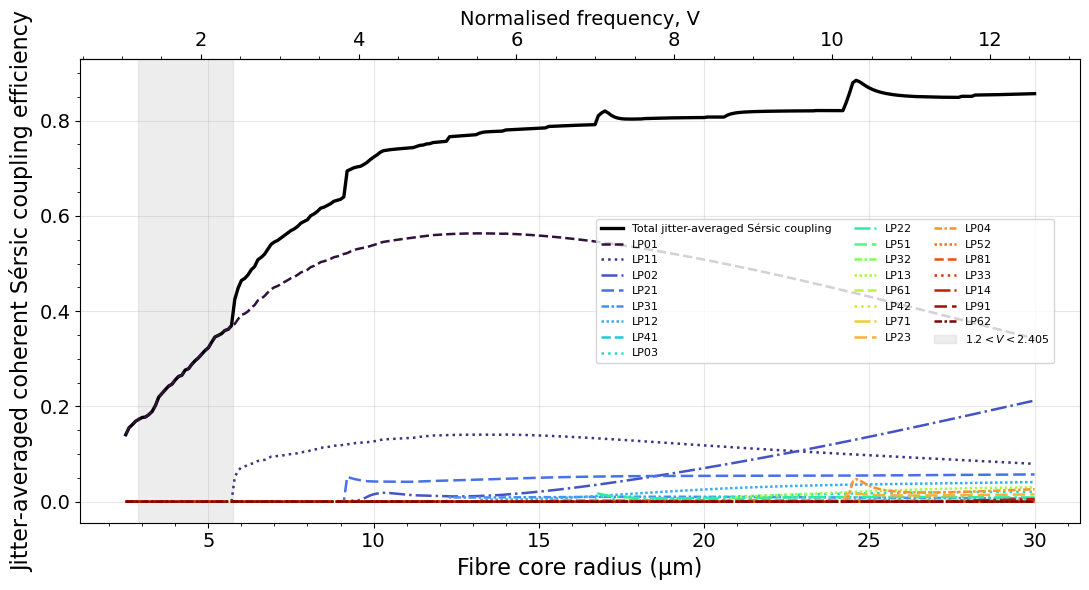

In [239]:
families_core_mask = plot_jittered_coherent_galaxy_lp_mode_families(
    core_radius_array=core_radius_range_full,
    results=results_jitter_per_mode_full,
    lam0=lam0,
    NA=NA,
    result_case="core_radius_mask",
    source_name="Sérsic",
)

In [202]:
# The background doesn't change, so import data 'results_bg_mmf_core_LIGHT'from the previous calculation.

results_bg_mmf_core = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_core_LIGHT.joblib')
eta_bg_core = np.array([res["eta_background"] for res in results_bg_mmf_core])# [:-1] # from zeroth index to second last index


results_bg_mmf_clad = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_clad_LIGHT.joblib')
eta_bg_cladding = np.array([res["eta_background"] for res in results_bg_mmf_clad])# [:-1] # from zeroth index to second last index

In [214]:
# SNR calculation for core case
core_radius_array = core_radius_range_full

eta_total_mean_core = np.array([
    result["core_radius_mask"]["eta_total_mean"]
    for result in results_jitter_per_mode_full
])

I_flat = 1**2  # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600  # conversion factor from radians to arcseconds

plate_scale_coude = (
    rad_to_arcsec / (F_focus * D_M1)
)  # arcseconds per meter at the focal plane

plate_scale_demag = (
    plate_scale_coude / Magnification
)  # arcseconds per meter at the fibre input plane


FOV_array_core = np.zeros_like(core_radius_array)
snr_array_core = np.zeros_like(core_radius_array)
signal_array_core = np.zeros_like(core_radius_array)
background_array_core = np.zeros_like(core_radius_array)


for i, a in enumerate(core_radius_array):

    # Calculate Field of View for the fibre.
    # plate scale = FOV / diameter,
    # therefore FOV = plate scale * fibre diameter.
    FOV_core = plate_scale_demag * 2 * a  # arcseconds

    # Geometric sky area subtended by the fibre core.
    Background_area_core = (
        np.pi
        * I_flat
        * (FOV_core / 2)**2
    )

    # Jitter-averaged coherent galaxy signal coupling.
    signal_core = eta_total_mean_core[i]

    # Background coupling efficiency for the core case.
    background_core = (
        eta_bg_core[i]
        # * I_flat
    )

    # Signal-to-noise ratio assuming background-dominated
    # Poisson noise.
    snr_core = signal_core / np.sqrt(
        Background_area_core
        * background_core
    )

    FOV_array_core[i] = FOV_core
    snr_array_core[i] = snr_core
    signal_array_core[i] = signal_core
    background_array_core[i] = background_core

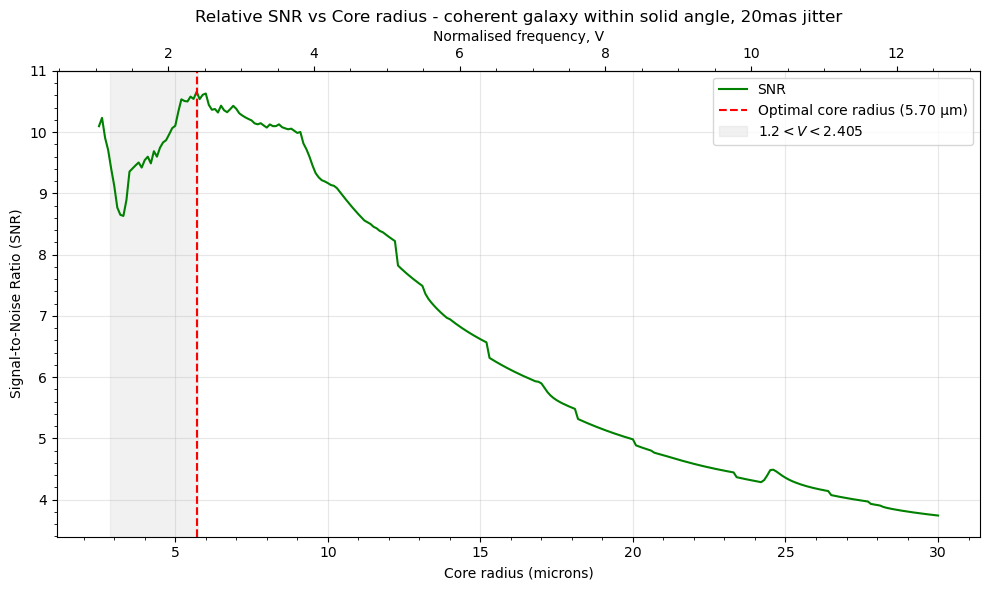

In [215]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(core_radius_array*1e6, snr_array_core, color='g', label='SNR')

ax1.axvline(core_radius_array[np.argmax(snr_array_core)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_array[np.argmax(snr_array_core)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR vs Core radius - coherent galaxy within solid angle, 20mas jitter')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um(V_1_2),
    V_to_radius_um(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
# plt.show()

plt.savefig(
    "/Users/tliu/oh_suppression/figures/PSF_Jitter_average_SNR_vs_Core_radius.png",
    dpi=300,
    bbox_inches="tight",
)

In [218]:
# SNR calculation for cladding case
eta_total_mean_cladding = np.array([
    result["no_mask"]["eta_total_mean"]
    for result in results_jitter_per_mode_full
])

FOV_array_cladding = np.zeros_like(core_radius_array)
snr_array_cladding = np.zeros_like(core_radius_array)
signal_array_cladding = np.zeros_like(core_radius_array)
background_array_cladding = np.zeros_like(core_radius_array)


for i, a in enumerate(core_radius_array):

    # Calculate Field of View for the fibre.
    FOV_cladding = plate_scale_demag * 2 * a  # arcseconds

    # Geometric sky area.
    Background_area_cladding = (
        np.pi
        * I_flat
        * (FOV_cladding / 2)**2
    )

    # Jitter-averaged coherent galaxy signal coupling.
    signal_cladding = eta_total_mean_cladding[i]

    # Background coupling efficiency for the cladding case.
    background_cladding = (
        eta_bg_cladding[i]
        # * I_flat
    )

    # Signal-to-noise ratio.
    # snr_cladding = signal_cladding / np.sqrt(
    #     Background_area_cladding
    #     * background_cladding
    # )
    snr_cladding = signal_cladding / background_cladding

    FOV_array_cladding[i] = FOV_cladding
    snr_array_cladding[i] = snr_cladding
    signal_array_cladding[i] = signal_cladding
    background_array_cladding[i] = background_cladding

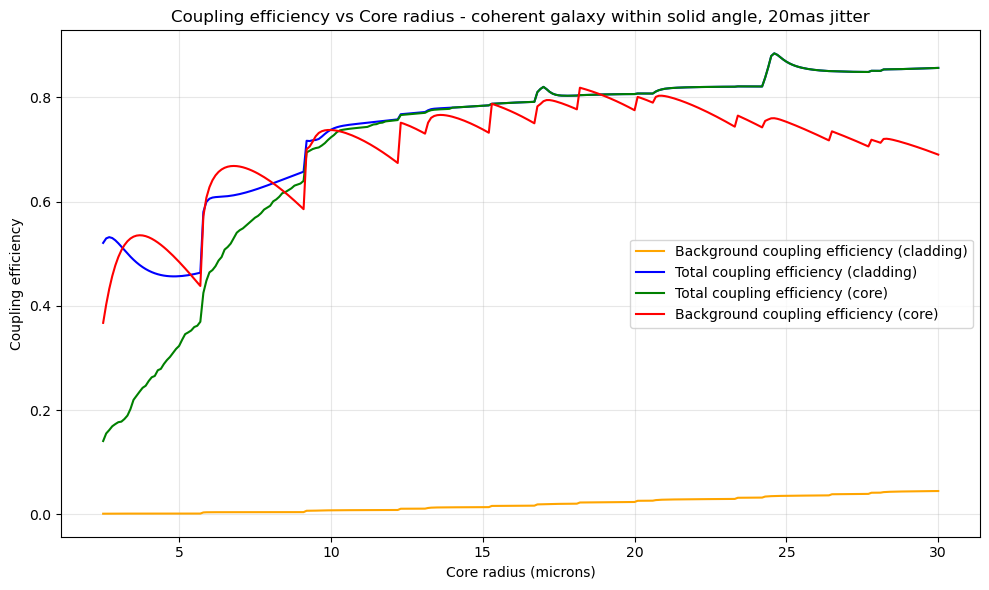

In [224]:
plt.figure(figsize=(10, 6))
plt.plot(core_radius_array*1e6, eta_bg_cladding, label='Background coupling efficiency (cladding)', color='orange')
plt.plot(core_radius_array*1e6, eta_total_mean_cladding, label='Total coupling efficiency (cladding)', color='blue')
plt.plot(core_radius_array*1e6, eta_total_mean_core, label='Total coupling efficiency (core)', color='green')
plt.plot(core_radius_array*1e6, eta_bg_core, label='Background coupling efficiency (core)', color='red')

plt.xlabel('Core radius (microns)')
plt.ylabel('Coupling efficiency')
plt.title('Coupling efficiency vs Core radius - coherent galaxy within solid angle, 20mas jitter')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()


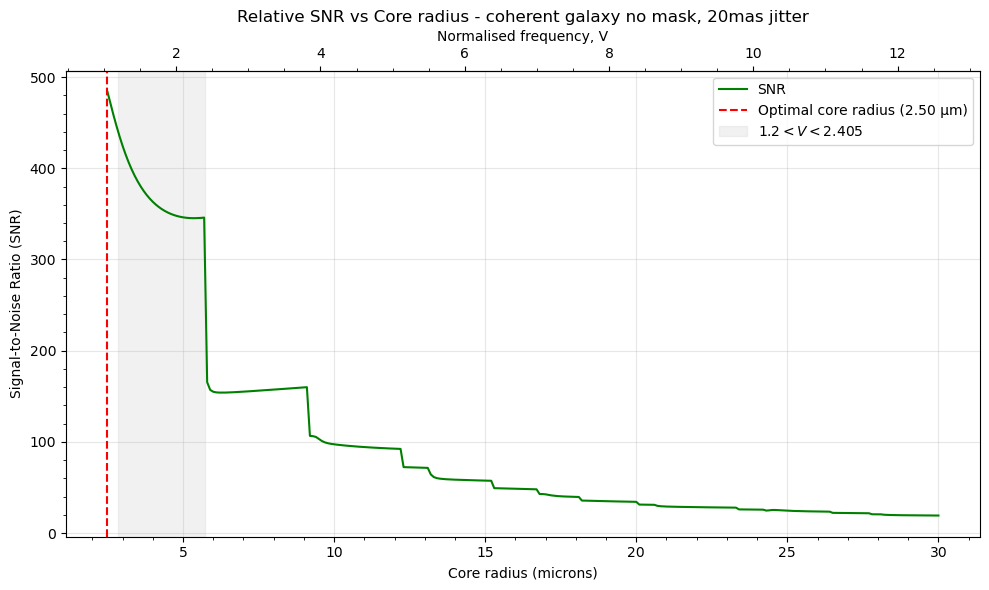

In [219]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(core_radius_array*1e6, snr_array_cladding, color='g', label='SNR')

ax1.axvline(core_radius_array[np.argmax(snr_array_cladding)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_array[np.argmax(snr_array)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR vs Core radius - coherent galaxy no mask, 20mas jitter')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um(V_1_2),
    V_to_radius_um(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
# plt.show()

plt.savefig(
    "/Users/tliu/oh_suppression/figures/PSF_Jitter_average_SNR_vs_Core_radius.png",
    dpi=300,
    bbox_inches="tight",
)